In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt



In [15]:
df = pd.read_csv('spam.csv', encoding='latin-1')

In [16]:
df.head()

,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN


In [17]:
df.columns

Index(['v1', 'v2', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4'], dtype='str')

In [18]:
df.isnull().sum()

v1               0
v2               0
Unnamed: 2    5522
Unnamed: 3    5560
Unnamed: 4    5566
dtype: int64

In [19]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   v1          5572 non-null   str  
 1   v2          5572 non-null   str  
 2   Unnamed: 2  50 non-null     str  
 3   Unnamed: 3  12 non-null     str  
 4   Unnamed: 4  6 non-null      str  
dtypes: str(5)
memory usage: 677.1 KB


In [20]:
df.shape

(5572, 5)

In [21]:
df.isna().sum()

v1               0
v2               0
Unnamed: 2    5522
Unnamed: 3    5560
Unnamed: 4    5566
dtype: int64

##
Data Cleaning

In [22]:
df = df.drop(columns=['Unnamed: 2','Unnamed: 3','Unnamed: 4']) 

In [23]:
df

,v1,v2
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."
...,...,...
5567,spam,This is the 2nd time we have tried 2 contact u...
5568,ham,Will Ì_ b going to esplanade fr home?
5569,ham,"Pity, * was in mood for that. So...any other s..."
5570,ham,The guy did some bitching but I acted like i'd...


In [24]:
df = df.rename(columns={'v1':"target",'v2':'text'})

In [25]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()

In [26]:
df

,target,text
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."
...,...,...
5567,spam,This is the 2nd time we have tried 2 contact u...
5568,ham,Will Ì_ b going to esplanade fr home?
5569,ham,"Pity, * was in mood for that. So...any other s..."
5570,ham,The guy did some bitching but I acted like i'd...


In [27]:
df['target'] = le.fit_transform(df['target'])

In [28]:
df

,target,text
0,0,"Go until jurong point, crazy.. Available only ..."
1,0,Ok lar... Joking wif u oni...
2,1,Free entry in 2 a wkly comp to win FA Cup fina...
3,0,U dun say so early hor... U c already then say...
4,0,"Nah I don't think he goes to usf, he lives aro..."
...,...,...
5567,1,This is the 2nd time we have tried 2 contact u...
5568,0,Will Ì_ b going to esplanade fr home?
5569,0,"Pity, * was in mood for that. So...any other s..."
5570,0,The guy did some bitching but I acted like i'd...


In [29]:
df.duplicated()

0       False
1       False
2       False
3       False
4       False
        ...  
5567    False
5568    False
5569    False
5570    False
5571    False
Length: 5572, dtype: bool

In [30]:
df.duplicated().sum()

np.int64(403)

In [31]:
df = df.drop_duplicates(keep='first')

In [32]:
df

,target,text
0,0,"Go until jurong point, crazy.. Available only ..."
1,0,Ok lar... Joking wif u oni...
2,1,Free entry in 2 a wkly comp to win FA Cup fina...
3,0,U dun say so early hor... U c already then say...
4,0,"Nah I don't think he goes to usf, he lives aro..."
...,...,...
5567,1,This is the 2nd time we have tried 2 contact u...
5568,0,Will Ì_ b going to esplanade fr home?
5569,0,"Pity, * was in mood for that. So...any other s..."
5570,0,The guy did some bitching but I acted like i'd...


In [33]:
df.shape

(5169, 2)

In [34]:
df['target'].value_counts()

target
0    4516
1     653
Name: count, dtype: int64

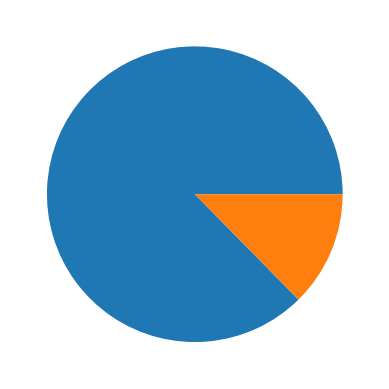

In [35]:
plt.pie(df['target'].value_counts())

In [36]:

import nltk



In [37]:
nltk.sent_tokenize("Hello. How are you? I am learning NLP.")

['Hello.', 'How are you?', 'I am learning NLP.']

In [38]:
df['num_characters'] = df['text'].apply(len)

# we will first do number of characters search

In [39]:
df

,target,text,num_characters
0,0,"Go until jurong point, crazy.. Available only ...",111
1,0,Ok lar... Joking wif u oni...,29
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,155
3,0,U dun say so early hor... U c already then say...,49
4,0,"Nah I don't think he goes to usf, he lives aro...",61
...,...,...,...
5567,1,This is the 2nd time we have tried 2 contact u...,161
5568,0,Will Ì_ b going to esplanade fr home?,37
5569,0,"Pity, * was in mood for that. So...any other s...",57
5570,0,The guy did some bitching but I acted like i'd...,125


## Now we will fetch number of words


In [40]:
def words(txt):
    word = txt.split()
    return len(word)
df['words'] = df['text'].apply(words)

In [41]:
df = df.drop(columns='words')

In [42]:
df

,target,text,num_characters
0,0,"Go until jurong point, crazy.. Available only ...",111
1,0,Ok lar... Joking wif u oni...,29
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,155
3,0,U dun say so early hor... U c already then say...,49
4,0,"Nah I don't think he goes to usf, he lives aro...",61
...,...,...,...
5567,1,This is the 2nd time we have tried 2 contact u...,161
5568,0,Will Ì_ b going to esplanade fr home?,37
5569,0,"Pity, * was in mood for that. So...any other s...",57
5570,0,The guy did some bitching but I acted like i'd...,125


In [43]:
df['words'] = df['text'].apply(lambda x:len(nltk.tokenize.word_tokenize(x)))

In [44]:
df

,target,text,num_characters,words
0,0,"Go until jurong point, crazy.. Available only ...",111,24
1,0,Ok lar... Joking wif u oni...,29,8
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,155,37
3,0,U dun say so early hor... U c already then say...,49,13
4,0,"Nah I don't think he goes to usf, he lives aro...",61,15
...,...,...,...,...
5567,1,This is the 2nd time we have tried 2 contact u...,161,35
5568,0,Will Ì_ b going to esplanade fr home?,37,9
5569,0,"Pity, * was in mood for that. So...any other s...",57,15
5570,0,The guy did some bitching but I acted like i'd...,125,27


In [45]:
df['sentences'] = df['text'].apply(lambda x:len(nltk.tokenize.sent_tokenize(x))) 

In [46]:
df

,target,text,num_characters,words,sentences
0,0,"Go until jurong point, crazy.. Available only ...",111,24,2
1,0,Ok lar... Joking wif u oni...,29,8,2
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,155,37,2
3,0,U dun say so early hor... U c already then say...,49,13,1
4,0,"Nah I don't think he goes to usf, he lives aro...",61,15,1
...,...,...,...,...,...
5567,1,This is the 2nd time we have tried 2 contact u...,161,35,4
5568,0,Will Ì_ b going to esplanade fr home?,37,9,1
5569,0,"Pity, * was in mood for that. So...any other s...",57,15,2
5570,0,The guy did some bitching but I acted like i'd...,125,27,1


In [47]:
df['text'][0]

'Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...'

In [48]:
df.describe()

,target,num_characters,words,sentences
count,5169.000000,5169.000000,5169.000000,5169.000000
mean,0.126330,78.977945,18.460437,1.965564
std,0.332253,58.236293,13.334441,1.448541
min,0.000000,2.000000,1.000000,1.000000
25%,0.000000,36.000000,9.000000,1.000000
50%,0.000000,60.000000,15.000000,1.000000
75%,0.000000,117.000000,26.000000,2.000000
max,1.000000,910.000000,220.000000,38.000000


In [49]:
df[df['target']==0].describe()

,target,num_characters,words,sentences
count,4516.0,4516.000000,4516.000000,4516.000000
mean,0.0,70.459256,17.128432,1.820195
std,0.0,56.358207,13.504730,1.383657
min,0.0,2.000000,1.000000,1.000000
25%,0.0,34.000000,8.000000,1.000000
50%,0.0,52.000000,13.000000,1.000000
75%,0.0,90.000000,22.000000,2.000000
max,0.0,910.000000,220.000000,38.000000


In [50]:
df[df['target']==1].describe()

,target,num_characters,words,sentences
count,653.0,653.000000,653.000000,653.000000
mean,1.0,137.891271,27.672282,2.970904
std,0.0,30.137753,7.010932,1.488425
min,1.0,13.000000,2.000000,1.000000
25%,1.0,132.000000,25.000000,2.000000
50%,1.0,149.000000,29.000000,3.000000
75%,1.0,157.000000,32.000000,4.000000
max,1.0,224.000000,46.000000,9.000000


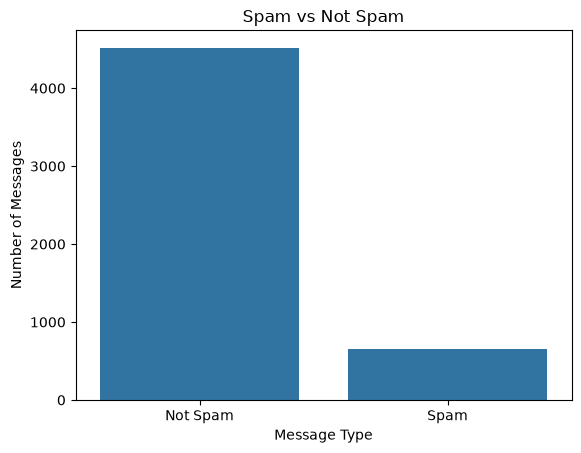

In [51]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.countplot(x='target', data=df)

plt.xlabel('Message Type')
plt.ylabel('Number of Messages')
plt.title('Spam vs Not Spam')

plt.xticks([0, 1], ['Not Spam', 'Spam'])
plt.show()

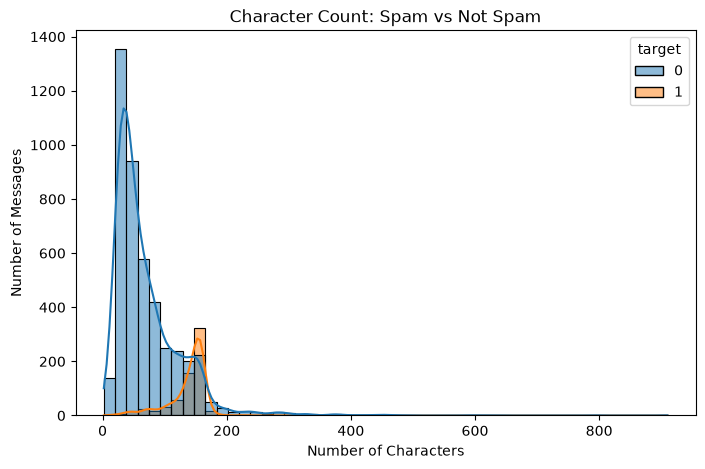

In [52]:
plt.figure(figsize=(8,5))

sns.histplot(
    data=df,
    x='num_characters',
    hue='target',
    bins=50,
    kde=True
)

plt.xlabel('Number of Characters')
plt.ylabel('Number of Messages')
plt.title('Character Count: Spam vs Not Spam')

plt.show()

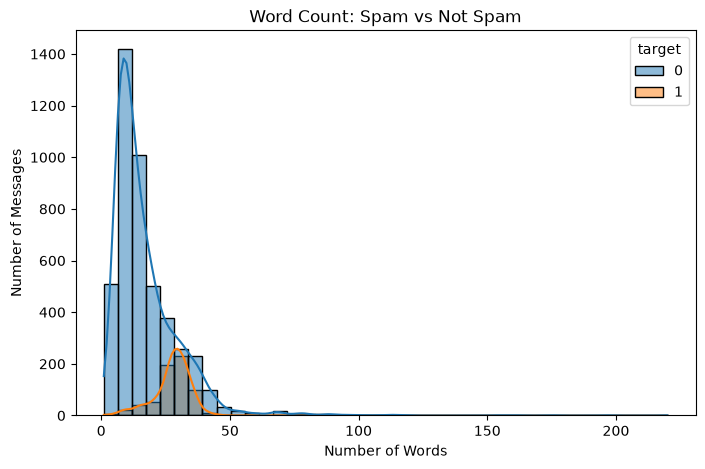

In [53]:
plt.figure(figsize=(8,5))

sns.histplot(
    data=df,
    x='words',
    hue='target',
    bins=40,
    kde=True
)

plt.xlabel('Number of Words')
plt.ylabel('Number of Messages')
plt.title('Word Count: Spam vs Not Spam')

plt.show()

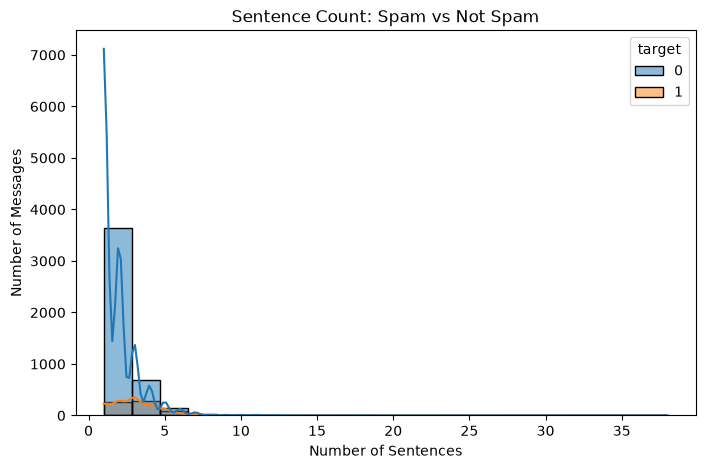

In [54]:
plt.figure(figsize=(8,5))

sns.histplot(
    data=df,
    x='sentences',
    hue='target',
    bins=20,
    kde=True
)

plt.xlabel('Number of Sentences')
plt.ylabel('Number of Messages')
plt.title('Sentence Count: Spam vs Not Spam')

plt.show()

In [77]:

import string
string.punctuation

'!"#$%&\'()*+,-./:;<=>?@[\\]^_`{|}~'

In [96]:
stop_words = set(stopwords.words('english'))

def transform(txt):
    txt = txt.lower()
    txt = nltk.word_tokenize(txt)

    txt = [word for word in txt if word.isalnum()]
    txt = [word for word in txt if word not in stop_words]
    txt = [ps.stem(word) for word in txt]

    return " ".join(txt)
    
    

In [97]:
transform('I loved the bird who was so loving about her love ones?')

'love bird love love one'

In [98]:
from nltk.corpus import stopwords

stopwords.words('english')[:20]


['i',
 'me',
 'my',
 'myself',
 'we',
 'our',
 'ours',
 'ourselves',
 'you',
 "you're",
 "you've",
 "you'll",
 "you'd",
 'your',
 'yours',
 'yourself',
 'yourselves',
 'he',
 'him',
 'his']

In [99]:
transform('Hi how are you Vatsal Shah?')

'hi vatsal shah'

In [100]:
from nltk.stem.porter import PorterStemmer
ps = PorterStemmer()
ps.stem('dancing')

'danc'

In [101]:
df['transformed'] = df['text'].apply(transform)

In [102]:
transform('Hi how are you Vatsal Shah?')

'hi vatsal shah'

In [103]:
df

,target,text,num_characters,words,sentences,transformed
0,0,"Go until jurong point, crazy.. Available only ...",111,24,2,go jurong point crazi avail bugi n great world...
1,0,Ok lar... Joking wif u oni...,29,8,2,ok lar joke wif u oni
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,155,37,2,free entri 2 wkli comp win fa cup final tkt 21...
3,0,U dun say so early hor... U c already then say...,49,13,1,u dun say earli hor u c alreadi say
4,0,"Nah I don't think he goes to usf, he lives aro...",61,15,1,nah think goe usf live around though
...,...,...,...,...,...,...
5567,1,This is the 2nd time we have tried 2 contact u...,161,35,4,2nd time tri 2 contact u pound prize 2 claim e...
5568,0,Will Ì_ b going to esplanade fr home?,37,9,1,b go esplanad fr home
5569,0,"Pity, * was in mood for that. So...any other s...",57,15,2,piti mood suggest
5570,0,The guy did some bitching but I acted like i'd...,125,27,1,guy bitch act like interest buy someth els nex...


In [105]:
%pip install wordcloud

Note: you may need to restart the kernel to use updated packages.


In [112]:
from wordcloud import WordCloud
wc = WordCloud(width=500,height=500,min_font_size=10,background_color='white')


In [113]:
spam_wc = wc.generate(df[df['target']==1]['transformed'].str.cat(sep=" "))

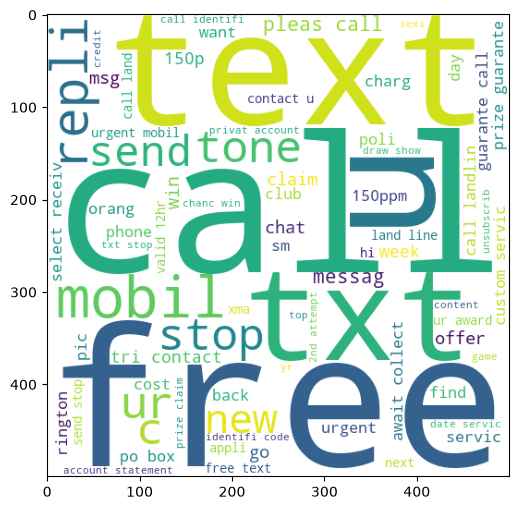

In [115]:
plt.figure(figsize=(12,6))
plt.imshow(spam_wc)

In [116]:
ham_wc = wc.generate(df[df['target']==0]['transformed'].str.cat(sep=" "))

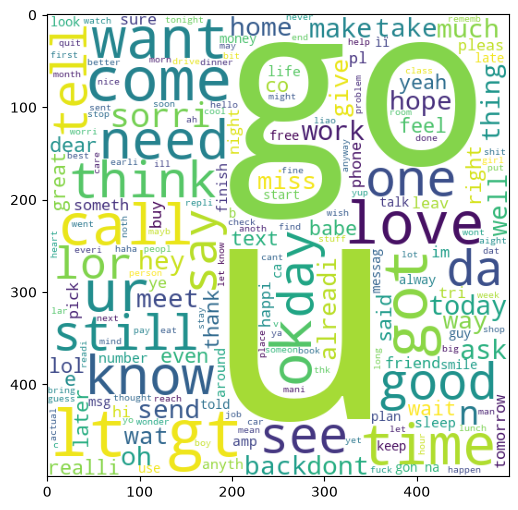

In [117]:
plt.figure(figsize=(12,6))
plt.imshow(spam_wc)

In [118]:
 df.head()

,target,text,num_characters,words,sentences,transformed
0,0,"Go until jurong point, crazy.. Available only ...",111,24,2,go jurong point crazi avail bugi n great world...
1,0,Ok lar... Joking wif u oni...,29,8,2,ok lar joke wif u oni
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,155,37,2,free entri 2 wkli comp win fa cup final tkt 21...
3,0,U dun say so early hor... U c already then say...,49,13,1,u dun say earli hor u c alreadi say
4,0,"Nah I don't think he goes to usf, he lives aro...",61,15,1,nah think goe usf live around though


In [124]:
spam_corpus= []
for msg in df[df['target']==1]['transformed'].tolist(): #pandas list se normal python list
    for words in msg.split(): #har ek msg ke words ko alag alag
        spam_corpus.append(words)
        

In [125]:
len(spam_corpus)

9942

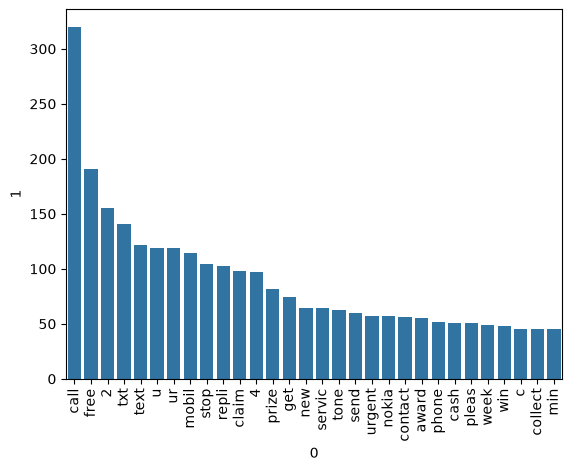

In [131]:
from collections import Counter

data = pd.DataFrame(Counter(spam_corpus).most_common(30))

sns.barplot(x=data[0], y=data[1])
plt.xticks(rotation='vertical')
plt.show()

In [136]:
ham_corpus= []
for msg in df[df['target']==0]['transformed'].tolist(): #pandas list se normal python list
    for words in msg.split(): #har ek msg ke words ko alag alag
        ham_corpus.append(words)

In [137]:
len(ham_corpus)

35423

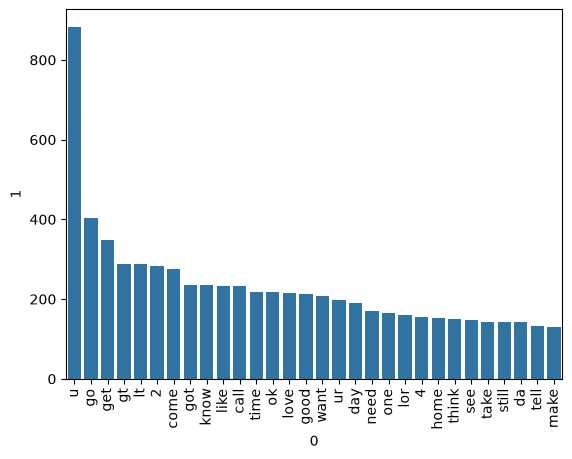

In [138]:
data = pd.DataFrame(Counter(ham_corpus).most_common(30))

sns.barplot(x=data[0], y=data[1])
plt.xticks(rotation='vertical')
plt.show()

In [148]:
df

,target,text,num_characters,words,sentences,transformed
0,0,"Go until jurong point, crazy.. Available only ...",111,24,2,go jurong point crazi avail bugi n great world...
1,0,Ok lar... Joking wif u oni...,29,8,2,ok lar joke wif u oni
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,155,37,2,free entri 2 wkli comp win fa cup final tkt 21...
3,0,U dun say so early hor... U c already then say...,49,13,1,u dun say earli hor u c alreadi say
4,0,"Nah I don't think he goes to usf, he lives aro...",61,15,1,nah think goe usf live around though
...,...,...,...,...,...,...
5567,1,This is the 2nd time we have tried 2 contact u...,161,35,4,2nd time tri 2 contact u pound prize 2 claim e...
5568,0,Will Ì_ b going to esplanade fr home?,37,9,1,b go esplanad fr home
5569,0,"Pity, * was in mood for that. So...any other s...",57,15,2,piti mood suggest
5570,0,The guy did some bitching but I acted like i'd...,125,27,1,guy bitch act like interest buy someth els nex...


# ab model building start karte hai

In [166]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
cv = CountVectorizer()
tfidf = TfidfVectorizer(max_features=3000)

In [141]:
X = cv.fit_transform(df['transformed']).toarray()

In [167]:
X2 = tfidf.fit_transform(df['transformed']).toarray()

In [160]:
X

array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]], shape=(5169, 6715))

In [143]:
y = df['target'].values

In [168]:
y2 = df['target'].values

In [144]:
y

array([0, 0, 1, ..., 0, 0, 0], shape=(5169,))

In [150]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=2
)

In [169]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score
X_train2, X_test2, y_train2, y_test2 = train_test_split(
    X2, y2, test_size=0.2, random_state=2
)

In [170]:
from sklearn.naive_bayes import GaussianNB, MultinomialNB, BernoulliNB
gnb = GaussianNB()
mnb = MultinomialNB()
bnb = BernoulliNB()


In [154]:
gnb.fit(X_train,y_train)
y_pred1 = gnb.predict(X_test)
print(accuracy_score(y_test,y_pred1))
print(confusion_matrix(y_test,y_pred1))
print(precision_score(y_test,y_pred1))


0.8800773694390716
[[792 104]
 [ 20 118]]
0.5315315315315315


In [164]:
gnb.fit(X_train2,y_train2)
y_pred_tfidf = gnb.predict(X_test2)
print(accuracy_score(y_test2,y_pred_tfidf))
print(confusion_matrix(y_test2,y_pred_tfidf))
print(precision_score(y_test2,y_pred_tfidf))


0.8762088974854932
[[793 103]
 [ 25 113]]
0.5231481481481481


In [155]:
mnb.fit(X_train,y_train)
y_pred2 = mnb.predict(X_test)
print(accuracy_score(y_test,y_pred2))
print(confusion_matrix(y_test,y_pred2))
print(precision_score(y_test,y_pred2))


0.9642166344294004
[[871  25]
 [ 12 126]]
0.8344370860927153


In [171]:
mnb.fit(X_train2,y_train2)
y_pred_tfidf2 = mnb.predict(X_test2)
print(accuracy_score(y_test2,y_pred_tfidf2))
print(confusion_matrix(y_test2,y_pred_tfidf2))
print(precision_score(y_test2,y_pred_tfidf2))


0.9709864603481625
[[896   0]
 [ 30 108]]
1.0


# because in email classifier we need PRECISION max, we are going to consider tfidf and MultinomialNB for our preffered model.



In [156]:
bnb.fit(X_train,y_train)
y_pred3 = bnb.predict(X_test)
print(accuracy_score(y_test,y_pred3))
print(confusion_matrix(y_test,y_pred3))
print(precision_score(y_test,y_pred3))


0.9700193423597679
[[893   3]
 [ 28 110]]
0.9734513274336283


In [156]:
bnb.fit(X_train,y_train)
y_pred3 = bnb.predict(X_test)
print(accuracy_score(y_test,y_pred3))
print(confusion_matrix(y_test,y_pred3))
print(precision_score(y_test,y_pred3))


0.9700193423597679
[[893   3]
 [ 28 110]]
0.9734513274336283


# trying to improve our model for higher accuracy

In [ ]:
# 1)change max features parametere of Tfidf to 300, we got accuracy to 97 and accuracy is still 1
# 2)by scaling our parameters in the vectorization, our accuracy DROPPED while precision rose by 0.7%
# 3)
